# Universidad de Buenos Aires
# Aprendizaje Profundo - TP2
# Cohorte 27 - 5to bimestre 2026

## **Alumno 1:** Astorga, Víctor Hugo

## **Alumno 2:** González, Isabel

## **Alumno 3:** Souto, Matías Agustín

El segundo TP tiene como plazo de entrega hasta las **23:59 hs del lunes 30 de noviembre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar tanto los contenidos vistos en clase, como otra bibliografía externa. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP2 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Importante permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local. Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/n85KQp4SRgcrgKMZ7)**. Tanto los resultados, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el colab.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP2.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP2-Co27.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP2-Co27.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# CASO: Adult Census Income

El objetivo del trabajo es construir un modelo de clasificación binaria que, a partir de los datos censales de diferentes hogares, determine si un individuo pertenece al grupo de mayores o de menores ingresos. Para ello, se empleará un conjunto de variables demográficas, laborales y socioeconómicas que describen las características de cada persona. El estudio debe incluir el análisis exploratorio del dataset, la selección y justificación de las transformaciones más adecuadas para cada variable, la construcción de modelos basados tanto en técnicas de codificación tradicionales como también en representaciones avanzadas mediante embeddings, y la comparación final del desempeño obtenido por cada enfoque.

**Para este caso de estudio, consideraremos como variable de alta cardinalidad a las que tengan 10 o más valores únicos.**


**Encontrarán el dataset en el siguiente enlace de drive: [link](https://drive.google.com/drive/folders/1S-usUXkJP6OdzUS0zdC5CW-XqegiXzln?usp=sharing)**

Está compuesto por los siguientes features:
- **age**: Edad del individuo expresada en años.

- **workclass**: Tipo de empleador o relación laboral del individuo. Describe si trabaja en el sector privado, gobierno estatal, local, federal, por cuenta propia, sin remuneración, etc.

- **education**: Nivel educativo alcanzado. Incluye categorías como secundaria completada, licenciatura, maestría, doctorado, etc.

- **marital-status**: Estado civil (casado, nunca casado, divorciado, viudo, etc.).

- **occupation**: Tipo de ocupación o área laboral, donde se incluye ventas, servicios de protección, técnicos, gerencia ejecutiva, fuerzas armadas, etc.

- **relationship**: Relación del individuo con el jefe del hogar como esposo, esposa, hijo propio, pariente, no familiar, etc.

- **race**: Autoidentificación racial como blanca, negra, indígena, asiática, isleños del Pacífico, entre otras.

- **sex**: Sexo biológico del individuo (masculino o femenino).

- **capital-gain**: Ingresos obtenidos por ganancia de capital (por ejemplo, venta de acciones o propiedades).

- **capital-loss**: Pérdidas declaradas por capital.

- **hours-per-week**: Cantidad de horas trabajadas por semana.

- **skill-profile**: Habilidad principal o conocmiento técnico adquirido que podría aplicar en el trabajo.

- **native-country**: País de nacimiento del individuo. Incluye Estados Unidos y una lista amplia de países del mundo.

- **income (target)**: Clasificación binaria que indica si el ingreso anual del individuo es menor o igual a 50K o mayor a 50K.

## a) Análisis exploratorio de los datasets (2 puntos)

- Realizar un EDA apoyado en gráficas adecuadas y coherentes para el caso de estudio.
- Analizar detalladamente los valores únicos de cada variable categórica e identificar su nivel de cardinalidad.
- Justificar de manera detallada el tipo de transformación que se le asignará a cada variable, en especial a las categóricas. **Dependiendo de su cardinalidad, su contexto y/o lógica interna de orden**, podrán transformarse mediante label/ordinal encoding, one-hot encoding o mediante una capa de embeddings dentro del modelo.
- No es necesario aplicar la misma transformación para todas las variables categóricas. El dataset puede (y debe) incluir diferentes tipos de transformaciones según las características de cada variable.
- Redactar explícitamente la decisión final adoptada para cada variable y su justificación correspondiente.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
data_train = pd.read_csv("./dataset/adult_train.csv")
data_test = pd.read_csv("./dataset/adult_val.csv")

In [2]:
data_train.head()

,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,skill-profile,native-country,income
0,39,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,manufacturing_assembly,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,accounting_bookkeeping,United-States,<=50K
2,38,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,agriculture_field_work,United-States,<=50K
3,53,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,office_data_entry_basic,United-States,<=50K
4,28,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,tech_programming_advanced,Cuba,<=50K


In [3]:
data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30162 entries, 0 to 30161
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             30162 non-null  int64
 1   workclass       30162 non-null  str  
 2   education       30162 non-null  str  
 3   marital-status  30162 non-null  str  
 4   occupation      30162 non-null  str  
 5   relationship    30162 non-null  str  
 6   race            30162 non-null  str  
 7   sex             30162 non-null  str  
 8   capital-gain    30162 non-null  int64
 9   capital-loss    30162 non-null  int64
 10  hours-per-week  30162 non-null  int64
 11  skill-profile   30162 non-null  str  
 12  native-country  30162 non-null  str  
 13  income          30162 non-null  str  
dtypes: int64(4), str(10)
memory usage: 3.2 MB


In [4]:
{
    col: data_train[col].unique() for col in data_train.columns
}

{'age': array([39, 50, 38, 53, 28, 37, 49, 52, 31, 42, 30, 23, 32, 34, 25, 43, 40,
        54, 35, 59, 56, 19, 20, 45, 22, 48, 21, 24, 57, 44, 41, 29, 47, 46,
        36, 79, 27, 18, 33, 76, 55, 61, 70, 64, 71, 66, 51, 58, 26, 17, 60,
        90, 75, 65, 77, 62, 63, 67, 74, 72, 69, 68, 73, 81, 78, 88, 80, 84,
        83, 85, 82, 86]),
 'workclass': <StringArray>
 [       'State-gov', 'Self-emp-not-inc',          'Private',
       'Federal-gov',        'Local-gov',     'Self-emp-inc',
       'Without-pay']
 Length: 7, dtype: str,
 'education': <StringArray>
 [   'Bachelors',      'HS-grad',         '11th',      'Masters',
           '9th', 'Some-college',   'Assoc-acdm',      '7th-8th',
     'Doctorate',    'Assoc-voc',  'Prof-school',      '5th-6th',
          '10th',    'Preschool',         '12th',      '1st-4th']
 Length: 16, dtype: str,
 'marital-status': <StringArray>
 [        'Never-married',    'Married-civ-spouse',              'Divorced',
  'Married-spouse-absent',            

Ninguna de las variables tiene nulls ni valores considerables como NaN. Se procede a hacer el análisis univariado

### Target


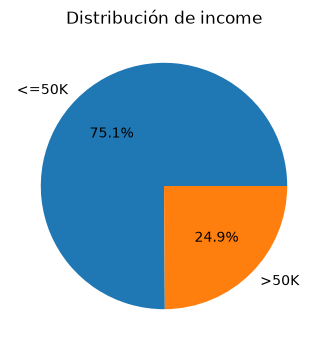

In [5]:
TARGET = "income"
def split_xy(df):
    return df.drop(TARGET, axis=1), df[TARGET]

X = data_train.drop(TARGET,axis=1)
y = data_train[TARGET]
X_train, X_test, y_train, y_test =train_test_split (X,y,test_size=0.2, random_state=123, stratify=y)
y_train.value_counts().plot.pie(autopct="%1.1f%%", figsize=(4,4))
plt.ylabel("")
plt.title("Distribución de income")
plt.show()

La variable target está con un leve desbalance en favor de los de bajos ingresos. Se calcula la entropía de shannon para ver si se justifica aplicar un rebalanceo

In [6]:
def shannon_entropy(y):
    probs = y.value_counts(normalize=True)
    return -np.sum(probs * np.log2(probs))

shannon_entropy(y_train)

np.float64(0.8095492820716506)

El resultado redondeado es 0.81, no se justifica aplicar resampling. Sin embargo, se va a calcular la `BCEWithLogitsLoss` con el `pos_weight` en la clase desbalanceada para que se factorice el desbalance en el cálculo de la pérdida. Es decir, se va a ponderar el peso de la clase minoritaria en lugar de tomar el conjunto. Para eso, el primer preprocesamiento será binarizar numéricamente la variable target. Se va a usar `joblib` para que las transformaciones se puedan reaplicar luego

In [7]:
import joblib
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler

target_encoder = LabelEncoder().fit(y_train)

#joblib.dump({"preprocessor": preprocessor, "target_encoder": target_encoder}, "preproc.joblib")

def transform_set(df, path="preproc.joblib"):
    art = joblib.load(path)
    X, y = split_xy(df)
    return art["preprocessor"].transform(X), art["target_encoder"].transform(y)

y_train_enc = target_encoder.transform(y_train)
y_train_enc

array([1, 0, 0, ..., 1, 0, 0], shape=(24129,))

In [8]:
y_train_enc = target_encoder.transform(y_train)
y_train_t = torch.tensor(y_train_enc, dtype=torch.float32)

n_pos = y_train_t.sum()
n_neg = len(y_train_t) - n_pos
pos_weight = (n_neg / n_pos).unsqueeze(0)

criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)


### Análisis de variables numéricas

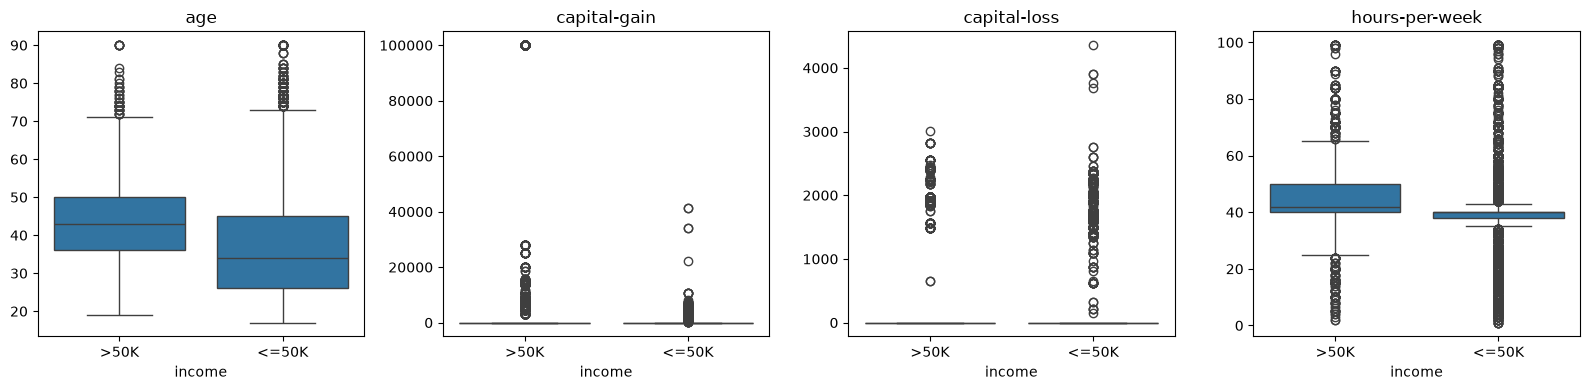

In [9]:
num_cols = X_train.select_dtypes(include="number").columns
fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=X_train, x=y_train, y=col, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Edad y horas trabajadas

In [10]:
X_train[["age","hours-per-week"]].describe()

,age,hours-per-week
count,24129.000000,24129.000000
mean,38.395002,40.980563
std,13.129416,11.963465
min,17.000000,1.000000
25%,28.000000,40.000000
50%,37.000000,40.000000
75%,47.000000,45.000000
max,90.000000,99.000000


<Axes: ylabel='Density'>

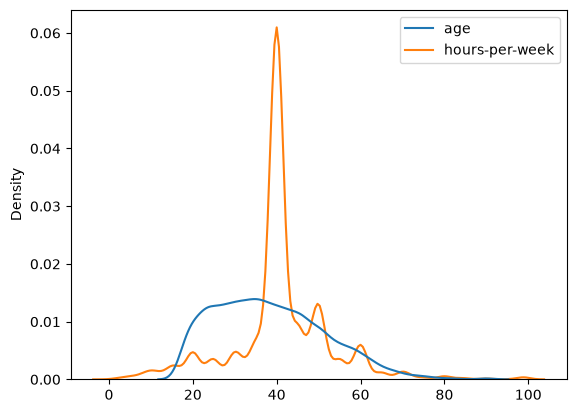

In [11]:
sns.kdeplot([X_train.age,X_train["hours-per-week"]])

In [12]:
X_train["hours-per-week"][X_train["hours-per-week"] > 90 ].value_counts()

hours-per-week
99    60
98     9
96     4
91     3
97     1
95     1
94     1
Name: count, dtype: int64

Ambas variables presentan asimetría positiva. Por otro lado, en el boxplot por income se observa que los individuos de mayores ingresos tienden a tener mayor edad y a trabajar más horas.

Respecto a la edad, la media se ubica en 38 años y la mediana en 37, con un desvío estándar de 13 años. La mitad central de la distribución está entre los 28 y los 47 años, con una cola que se estira hacia los más ancianos.

Las horas trabajadas también se centran alrededor de las 40 horas. Nótese que el primer cuartil ya llega a las 40, así que se puede deducir que la gran mayoría de los encuestados trabajan full time. El pico de horas en 99 parece ser algo de codificación.

A pesar de todo, al estandarizar, los valores extremos terminan teniendo magnitudes manejables para una red neuronal: (99 - 41) / 12 = 4.8

### Capital gain y loss

En este caso, hay una gran parte del dataset que no tiene ganancias ni pérdidas de capital. Por eso, se va a crear una variable auxiliar de "works-with-capital" booleana como la unión entre ambas

In [13]:
X_train["works-with-capital"] = ((X_train["capital-gain"] > 0) | (X_train["capital-loss"] > 0)).astype(int)
X_train[["works-with-capital","capital-gain","capital-loss"]].head()

,works-with-capital,capital-gain,capital-loss
21205,0,0,0
22154,1,1506,0
28987,0,0,0
18922,0,0,0
26025,0,0,0


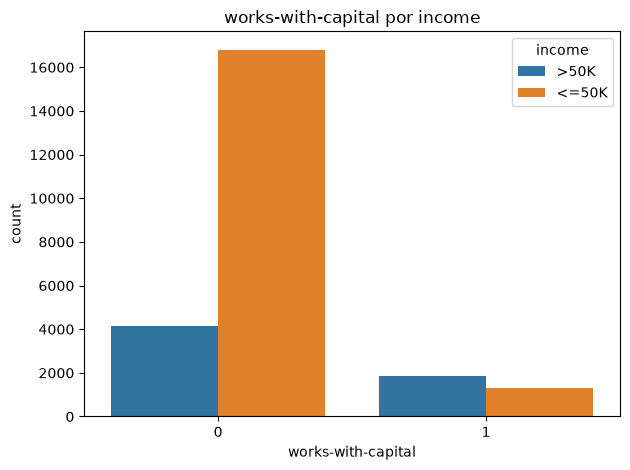

In [14]:
fig, ax = plt.subplots()
sns.countplot(x=X_train["works-with-capital"], hue=y_train, ax=ax)
ax.set_title("works-with-capital por income")
ax.set_xlabel("works-with-capital")
plt.tight_layout()
plt.show()

In [15]:
# P(income | works-with-capital): de los que trabajan (o no) con capital, qué proporción gana >50K
pd.crosstab(X_train["works-with-capital"], y_train, normalize="index")

income,<=50K,>50K
works-with-capital,,
0,0.802521,0.197479
1,0.412873,0.587127


In [16]:
# P(works-with-capital | income): dentro de cada clase de income, qué proporción trabaja con capital
pd.crosstab(X_train["works-with-capital"], y_train, normalize="columns")

income,<=50K,>50K
works-with-capital,,
0,0.92744,0.688645
1,0.07256,0.311355


In [17]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """V de Cramér entre dos variables categóricas. Devuelve (V, p-valor del test chi2)."""
    tabla = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(tabla, correction=False)
    n = tabla.values.sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k)), p

v, p = cramers_v(X_train["works-with-capital"], y_train)
print(f"V de Cramér = {v:.3f}  (p = {p:.2e})")

V de Cramér = 0.305  (p = 0.00e+00)


El trabajar con capital está moderadamente asociado a >50K (V de Cramér = 0.305, p < 0.001). De los que trabajan con capital, el 59% gana más de 50K, contra solo el 20% de los que no lo hacen.

Visto desde el target: el 31% de los que ganan >50K trabaja con capital, frente a apenas el 7% de los que ganan <=50K. Es decir, que la ausencia de capital no descarta altos ingresos (el 69% de los >50K no trabaja con capital), pero su presencia es un buen indicio de ellos. Esta variable booleana incorpora la información suficiente para distinguir el target. Independientemente de los valores que tomen gain y loss, lo que más importa es si son mayores  a cero 

---

### Análisis de variables categóricas

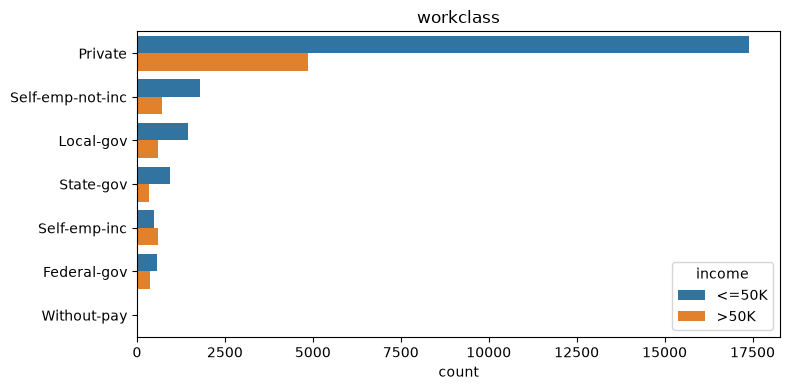

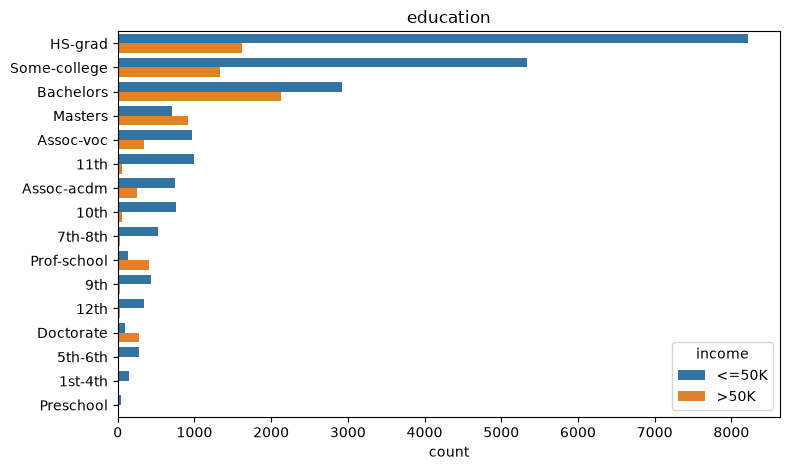

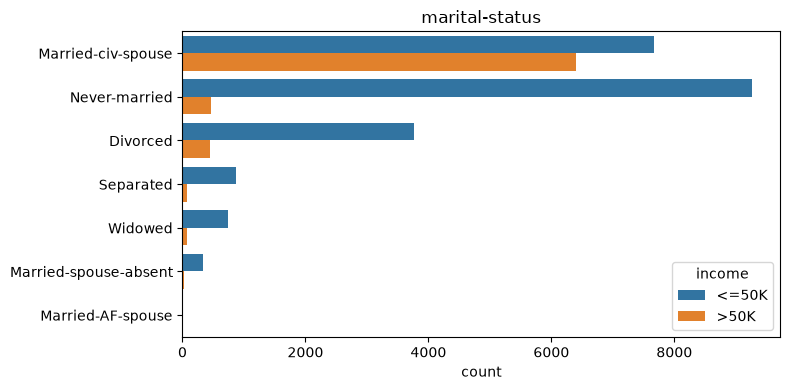

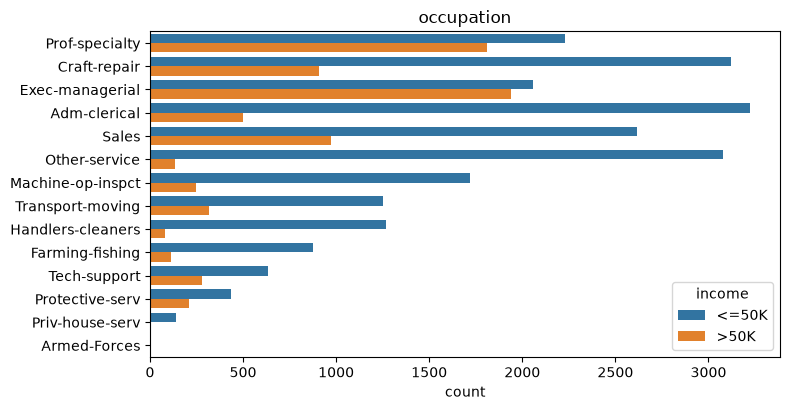

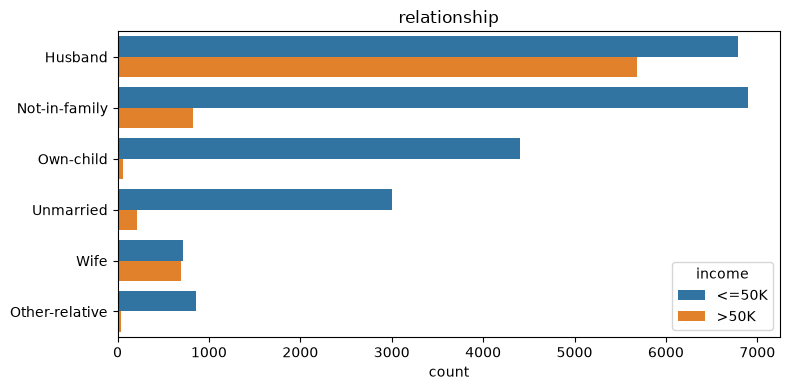

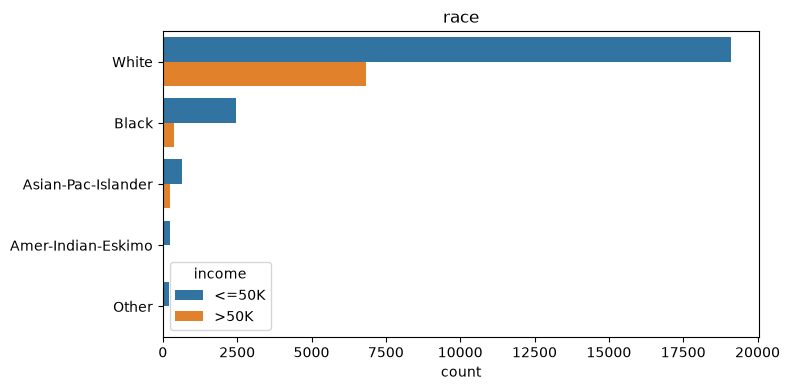

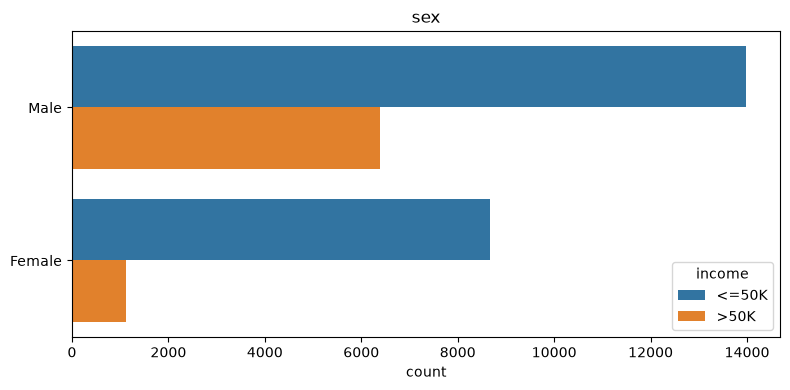

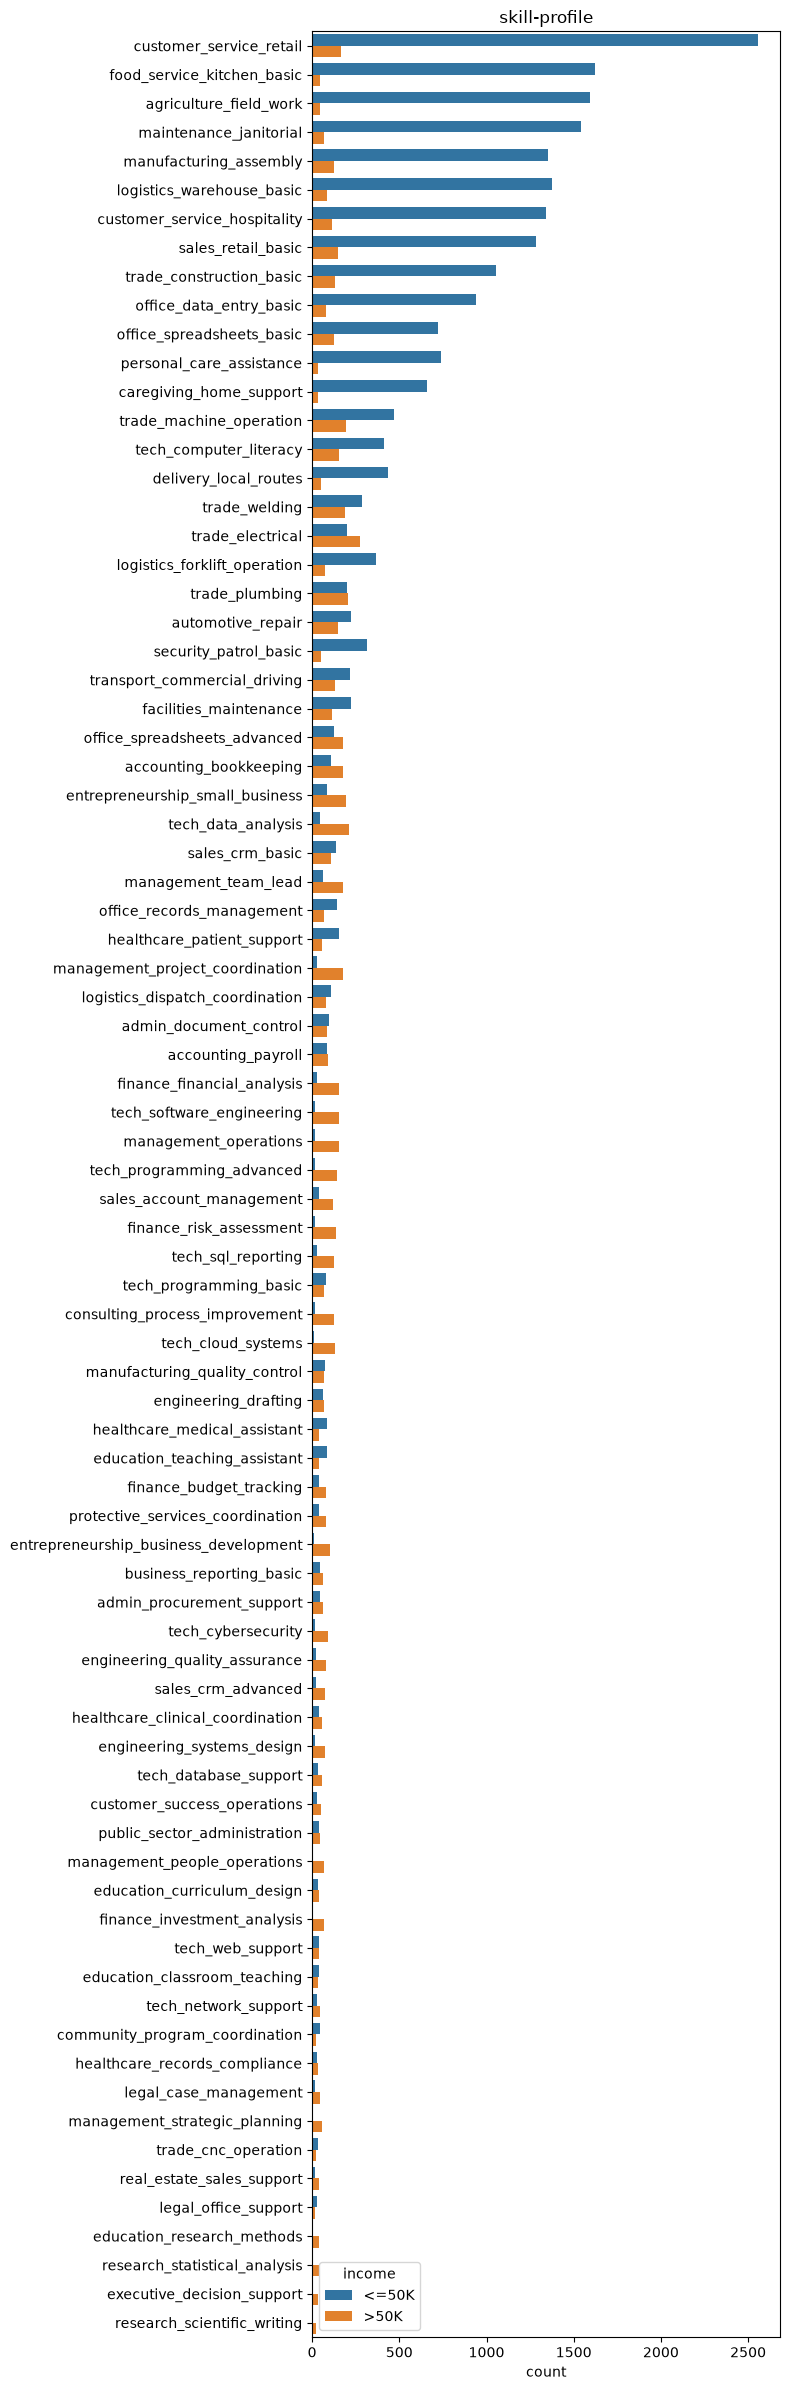

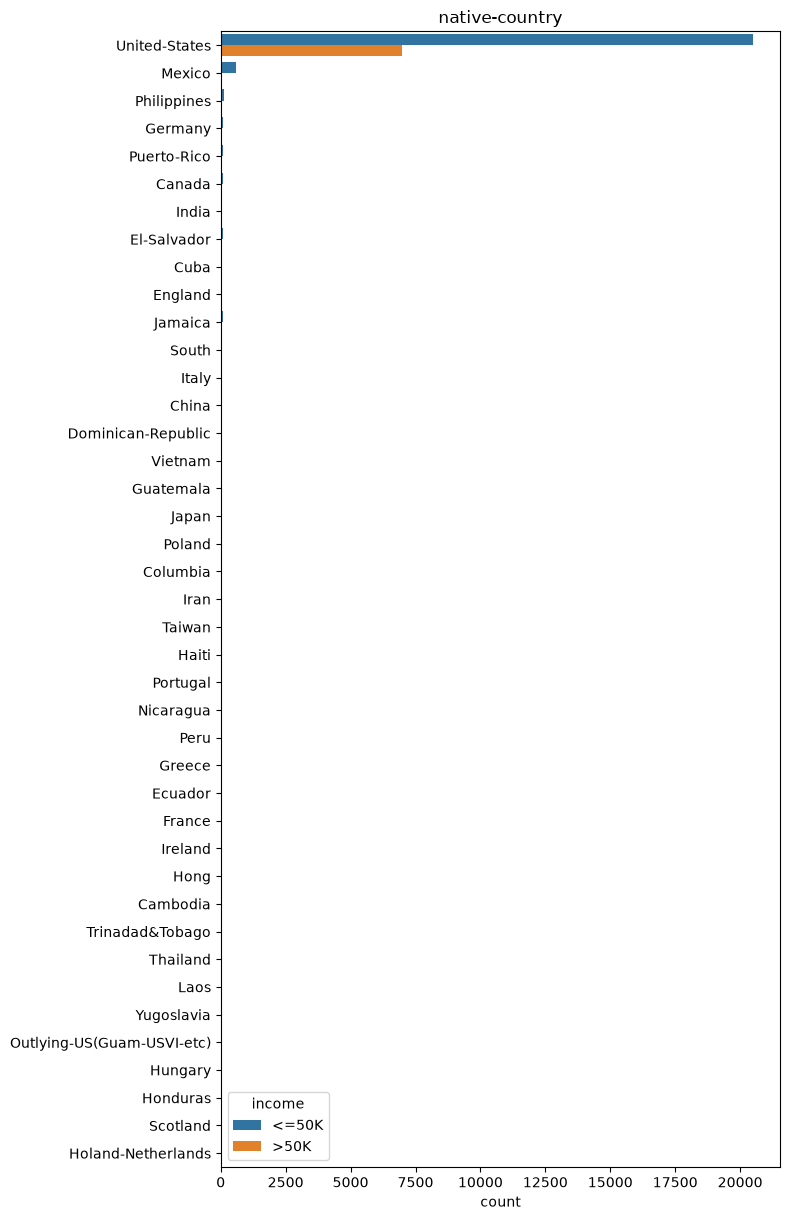

In [18]:
cat_cols = data_train.select_dtypes(exclude="number").columns.drop("income")

for col in cat_cols:
    order = data_train[col].value_counts().index
    height = max(4, 0.3 * len(order))
    plt.figure(figsize=(8, height))
    sns.countplot(data=data_train, y=col, hue="income", order=order)
    plt.title(col)
    plt.xlabel("count")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

### Workclass

### Redundancia en variables de género

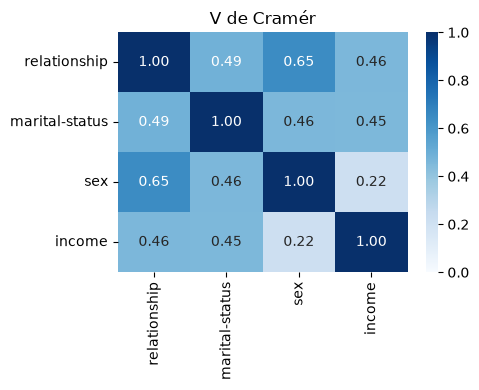

sex,Female,Male
relationship,,
Husband,1,9945
Not-in-family,2850,3344
Other-relative,306,405
Own-child,1580,2019
Unmarried,1938,608
Wife,1132,1


marital-status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,9,9937,0,0,0,0
Not-in-family,1833,0,11,138,3565,305,342
Other-relative,87,1,90,22,432,46,33
Own-child,244,1,65,36,3165,78,10
Unmarried,1213,0,0,103,644,316,270
Wife,0,7,1126,0,0,0,0


In [19]:
gender_related_cols = ["relationship", "marital-status", "sex"]
gender_df = X_train[gender_related_cols].assign(income=y_train)
compared_cols = gender_related_cols + ["income"]

# Matriz de V de Cramér entre pares (incluyendo el target como referencia)
cramers_v_matrix = pd.DataFrame(index=compared_cols, columns=compared_cols, dtype=float)
for row_col in compared_cols:
    for column_col in compared_cols:
        cramers_v_matrix.loc[row_col, column_col] = cramers_v(gender_df[row_col], gender_df[column_col])[0]

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cramers_v_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("V de Cramér")
plt.tight_layout()
plt.show()

# Tablas cruzadas para ver de dónde sale la redundancia
display(pd.crosstab(X_train["relationship"], X_train["sex"]))
display(pd.crosstab(X_train["relationship"], X_train["marital-status"]))

In [20]:
# ¿Cuánta señal aporta relationship que marital-status no captura?
# Se mide dentro de Never-married, donde relationship separa Own-child de Not-in-family
never_married_mask = X_train["marital-status"] == "Never-married"
never_married_relationship = X_train.loc[never_married_mask, "relationship"]
never_married_income = y_train[never_married_mask]

never_married_v, never_married_p = cramers_v(never_married_relationship, never_married_income)
print(f"V de Crámer relationship vs income (Never-married) = {never_married_v:.3f}  (p = {never_married_p:.2e})")

display(pd.crosstab(never_married_relationship, never_married_income, normalize="index"))
display(X_train.loc[never_married_mask].groupby("relationship")["age"].median().rename("mediana de edad"))

V de Crámer relationship vs income (Never-married) = 0.186  (p = 3.08e-58)


income,<=50K,>50K
relationship,,
Not-in-family,0.912482,0.087518
Other-relative,0.988426,0.011574
Own-child,0.993681,0.006319
Unmarried,0.968944,0.031056


relationship
Not-in-family     29.0
Other-relative    24.0
Own-child         22.0
Unmarried         31.0
Name: mediana de edad, dtype: float64

Las tres variables están asociadas entre sí, siendo `relationship` y `sex` el par más redundante (V = 0.65). Husband es Male en prácticamente todos los casos y Wife es Female. A su vez, Husband y Wife implican `Married-civ-spouse`, por lo que la combinación de `marital-status` y `sex` reconstruye casi exactamente esas dos categorías, que representan cerca de la mitad del dataset. Cabe aclarar que la implicación va en un solo sentido: `relationship` determina `marital-status` para Husband y Wife, pero no al revés, y es por eso que la V entre ambas (0.49) subestima la redundancia. Además, `relationship` describe a la persona respecto del jefe de hogar, es decir que depende de quién figure como referencia en el censo, mientras que `sex` y `marital-status` son atributos del propio individuo y permiten analizar cada registro de forma independiente. Por estos motivos se decide conservar `sex` y `marital-status` y descartar `relationship`, sin perder capacidad explicativa sobre el target: `marital-status` tiene una asociación con income (V = 0.45) prácticamente igual a la de `relationship` (V = 0.46).

El costo de esta decisión es la categoría `Own-child`, que `marital-status` no distingue: dentro de `Never-married`, quienes viven con sus padres casi nunca superan los 50K (0.6%), contra un 8.8% de los Not-in-family. Sin embargo, la señal que se pierde es acotada. Dentro de `Never-married` la asociación de `relationship` con income es débil (V = 0.19), ya que ese grupo es de por sí mayoritariamente de bajos ingresos (95% <=50K). Por otro lado, gran parte de esa información la recupera `age`, porque los `Own-child` son notoriamente más jóvenes (mediana de 22 años contra 29 de los Not-in-family).

### Education

`education` tiene 16 valores únicos por lo que, según el criterio, es de alta cardinalidad. Sin embargo, a diferencia del resto de las variables de alta cardinalidad, sus categorías tienen un orden natural, de `Preschool` a `Doctorate`. Por eso se aplica un ordinal encoding con el orden explícito, tomado de la columna `education-num` del dataset Adult original ([UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/2/adult)), que en esta versión no está incluida. De esta forma, la red recibe el orden ya resuelto en una sola entrada, en lugar de tener que aprenderlo a partir de un embedding o de 16 columnas one-hot.

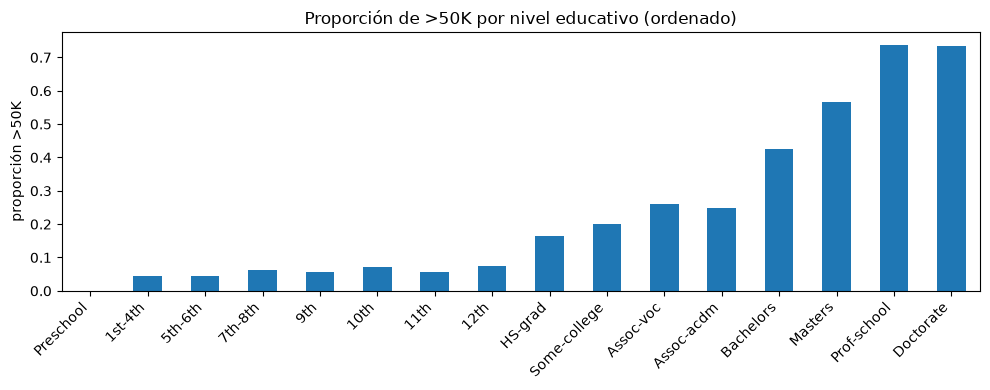

In [21]:
education_order = [
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm",
    "Bachelors", "Masters", "Prof-school", "Doctorate",
]

education_encoder = OrdinalEncoder(categories=[education_order]).fit(X_train[["education"]])

education_level = pd.Series(
    education_encoder.transform(X_train[["education"]]).ravel().astype(int),
    index=X_train.index,
    name="education-level",
)

high_income_rate_by_level = (y_train == ">50K").groupby(education_level).mean()

fig, ax = plt.subplots(figsize=(10, 4))
high_income_rate_by_level.plot.bar(ax=ax)
ax.set_xticks(range(len(education_order)))
ax.set_xticklabels(education_order, rotation=45, ha="right")
ax.set_xlabel("")
ax.set_ylabel("proporción >50K")
ax.set_title("Proporción de >50K por nivel educativo (ordenado)")
plt.tight_layout()
plt.show()

La proporción de altos ingresos acompaña el orden propuesto. Hasta `12th` se mantiene baja y casi plana. Da un salto en `HS-grad` y a partir de ahí crece de forma sostenida. Las pequeñas inversiones (`Assoc-voc` levemente por encima de `Assoc-acdm`, `Prof-school` y `Doctorate` prácticamente iguales) se dan entre niveles contiguos y no contradicen la tendencia general, lo que respalda la codificación ordinal. Al igual que las variables numéricas, el nivel resultante (0 a 15) se estandarizará antes de ingresar a la red.

### Variables de alta cardinalidad sin orden: embeddings

`occupation` (14 valores), `native-country` (41) y `skill-profile` (80) son de alta cardinalidad y no tienen un orden lógico entre sus categorías, por lo que se representan mediante capas de embedding. Un one-hot les agregaría 135 columnas ralas y trataría a todas las categorías como equidistantes, mientras que un embedding aprende un vector denso de baja dimensión en el que categorías con un comportamiento similar respecto del target quedan cerca.

Para alimentar las capas de embedding, cada categoría se codifica como un índice entero. Se reserva el índice 0 para categorías no vistas en entrenamiento, de modo que el modelo no falle si en validación aparece un valor nuevo; las categorías conocidas ocupan los índices 1 a n. Por lo tanto, cada embedding tiene n + 1 filas.

**Dimensión de los embeddings.** Se adopta la regla empírica que usa la librería fast.ai para elegir el tamaño de los embeddings en datos tabulares, implementada en la función `emb_sz_rule`:

$$d = \min\left(600,\ \text{round}\left(1.6 \cdot n^{0.56}\right)\right)$$

donde $n$ es la cardinalidad de la variable. Según la documentación de fast.ai, es una regla obtenida *"through trial and error"*. El exponente 0.56 hace que la dimensión crezca de forma sublineal (aproximadamente como $\sqrt{n}$): las variables con más categorías reciben más dimensiones, pero siempre muy por debajo de $n$, lo que garantiza una compresión real respecto del one-hot. El tope de 600 solo actúa en cardinalidades muy grandes y no aplica en este caso.

| Variable | $n$ (con desconocida) | $1.6 \cdot n^{0.56}$ | $d$ | Columnas one-hot equivalentes |
|---|---|---|---|---|
| `occupation` | 15 | 7.3 | 7 | 14 |
| `native-country` | 42 | 13.0 | 13 | 41 |
| `skill-profile` | 81 | 18.7 | 19 | 80 |
| **Total** | | | **39** | **135** |

La propia documentación aclara que es un punto de partida y que *"it is not uncommon for slight adjustments to this general formula to provide more success"*, por lo que la dimensión puede ajustarse según el comportamiento del modelo.

Fuentes:
- fast.ai, documentación del módulo `tabular.model`, sección *Embeddings*: https://docs.fast.ai/tabular.model.html
- Implementación de `emb_sz_rule` en el código fuente de fast.ai: https://github.com/fastai/fastai/blob/master/fastai/tabular/model.py
- Howard, J. & Gugger, S. (2020). *fastai: A Layered API for Deep Learning*. Information, 11(2), 108. https://doi.org/10.3390/info11020108

In [22]:
UNKNOWN_CATEGORY_INDEX = 0
embedding_cols = ["occupation", "native-country", "skill-profile"]

embedding_index_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=UNKNOWN_CATEGORY_INDEX - 1,
).fit(X_train[embedding_cols])

def to_embedding_indices(df):
    """Convierte las columnas de embedding a índices enteros (0 = desconocida, 1..n = categorías de train)."""
    category_indices = embedding_index_encoder.transform(df[embedding_cols]) + 1
    return torch.tensor(category_indices, dtype=torch.long)

def fastai_embedding_dim(cardinality):
    return min(600, round(1.6 * cardinality ** 0.56))

embedding_cardinalities = [len(categories) + 1 for categories in embedding_index_encoder.categories_]
embedding_dims = [fastai_embedding_dim(cardinality) for cardinality in embedding_cardinalities]

pd.DataFrame(
    {"cardinalidad (con desconocida)": embedding_cardinalities, "dimensión embedding": embedding_dims},
    index=embedding_cols,
)

,cardinalidad (con desconocida),dimensión embedding
occupation,15,7
native-country,42,13
skill-profile,81,19


In [23]:
import torch.nn as nn

class CategoricalEmbeddings(nn.Module):
    """Una capa nn.Embedding por variable categórica; concatena los vectores resultantes."""

    def __init__(self, cardinalities, dims):
        super().__init__()
        self.embedding_layers = nn.ModuleList(
            nn.Embedding(cardinality, dim) for cardinality, dim in zip(cardinalities, dims)
        )
        self.output_dim = sum(dims)

    def forward(self, category_indices):
        # category_indices: [batch, n_columnas] de tipo long
        embedded_columns = [
            embedding_layer(category_indices[:, column_position])
            for column_position, embedding_layer in enumerate(self.embedding_layers)
        ]
        return torch.cat(embedded_columns, dim=1)

categorical_embeddings = CategoricalEmbeddings(embedding_cardinalities, embedding_dims)

sample_indices = to_embedding_indices(X_train.head())
sample_embedded = categorical_embeddings(sample_indices)

print(categorical_embeddings)
print(f"Entrada: {tuple(sample_indices.shape)} índices -> salida: {tuple(sample_embedded.shape)}")
print(f"Parámetros de los embeddings: {sum(parameter.numel() for parameter in categorical_embeddings.parameters())}")

CategoricalEmbeddings(
  (embedding_layers): ModuleList(
    (0): Embedding(15, 7)
    (1): Embedding(42, 13)
    (2): Embedding(81, 19)
  )
)
Entrada: (5, 3) índices -> salida: (5, 39)
Parámetros de los embeddings: 2190


### Pipeline de preprocesamiento

Se reúnen todas las decisiones anteriores en un único `ColumnTransformer`, que se ajusta solo con el set de entrenamiento y se guarda con `joblib` para reaplicarlo sin volver a ajustar:

| Variable | Transformación |
|---|---|
| `age`, `hours-per-week` | `StandardScaler` |
| `capital-gain`, `capital-loss` | se reemplazan por el flag `works-with-capital` |
| `education` | ordinal (orden de `education-num`) + `StandardScaler` |
| `workclass`, `marital-status`, `race`, `sex` | one-hot (baja cardinalidad, sin orden) |
| `occupation`, `native-country`, `skill-profile` | índices enteros para embedding (0 = categoría desconocida) |
| `relationship` | se descarta |

Las columnas de embedding quedan al final de la matriz transformada, para que el modelo pueda separarlas del resto. `build_preprocessor` recibe los grupos de variables como parámetro, de modo que el modelo del punto c) pueda reutilizarla moviendo las variables de embedding al grupo one-hot.

Nota: las funciones auxiliares (`flag_works_with_capital`, etc.) se guardan por referencia, así que para cargar el `.joblib` tienen que estar definidas en la sesión.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

PREPROCESSING_PATH = "preproc.joblib"

def flag_works_with_capital(capital_columns):
    """1 si tiene ganancia o pérdida de capital, 0 si no."""
    return (np.asarray(capital_columns) > 0).any(axis=1).astype(int).reshape(-1, 1)

def works_with_capital_feature_name(transformer, input_features):
    return np.array(["works-with-capital"])

def reserve_unknown_index(category_indices):
    """Corre los índices en 1: el desconocido (-1) pasa a 0 y las categorías conocidas a 1..n."""
    return category_indices + 1

def build_preprocessor(feature_groups):
    ordinal_cols = list(feature_groups["ordinal"].keys())
    ordinal_categories = list(feature_groups["ordinal"].values())
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), feature_groups["numeric"]),
            ("capital", FunctionTransformer(flag_works_with_capital, feature_names_out=works_with_capital_feature_name),
             feature_groups["capital"]),
            ("ordinal", Pipeline([
                ("encode", OrdinalEncoder(categories=ordinal_categories)),
                ("scale", StandardScaler()),
            ]), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), feature_groups["onehot"]),
            # Las de embedding van al final para poder separarlas en el modelo
            ("embedding", Pipeline([
                ("index", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                ("reserve_unknown", FunctionTransformer(reserve_unknown_index, feature_names_out="one-to-one")),
            ]), feature_groups["embedding"]),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

FEATURE_GROUPS_WITH_EMBEDDINGS = {
    "numeric": ["age", "hours-per-week"],
    "capital": ["capital-gain", "capital-loss"],
    "ordinal": {"education": education_order},
    "onehot": ["workclass", "marital-status", "race", "sex"],
    "embedding": ["occupation", "native-country", "skill-profile"],
}

# --- fit solo con train y guardar ---
preprocessor = build_preprocessor(FEATURE_GROUPS_WITH_EMBEDDINGS).fit(X_train)
target_encoder = LabelEncoder().fit(y_train)
joblib.dump({"preprocessor": preprocessor, "target_encoder": target_encoder}, PREPROCESSING_PATH)

# --- cargar y aplicar a cualquier set ---
def transform_features_target(features, target, path=PREPROCESSING_PATH):
    preprocessing = joblib.load(path)
    return preprocessing["preprocessor"].transform(features), preprocessing["target_encoder"].transform(target)

X_train_processed, y_train_processed = transform_features_target(X_train, y_train)
X_test_processed, y_test_processed = transform_features_target(X_test, y_test)
X_val_processed, y_val_processed = transform_set(data_test)

print("Columnas de salida:", list(preprocessor.get_feature_names_out()))
print(f"train: {X_train_processed.shape}  test: {X_test_processed.shape}  validación: {X_val_processed.shape}")

Columnas de salida: ['age', 'hours-per-week', 'works-with-capital', 'education', 'workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'workclass_Without-pay', 'marital-status_Divorced', 'marital-status_Married-AF-spouse', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'race_Amer-Indian-Eskimo', 'race_Asian-Pac-Islander', 'race_Black', 'race_Other', 'race_White', 'sex_Female', 'sex_Male', 'occupation', 'native-country', 'skill-profile']
train: (24129, 28)  test: (6033, 28)  validación: (15060, 28)


## b) Diseño y entrenamiento de un modelo con embeddings (3 puntos)

- Implementar las transformaciones definidas en el punto anterior e incorporarlas al flujo de entrenamiento.
- El modelo debe incluir, como mínimo, una capa de embedding para representar alguna de las variables categóricas.
- La elección de la dimensión del o los embeddings queda a criterio del estudiante, pero debe estar correctamente fundamentada. Recuerden que no es obligatorio que todos los embeddings tengan la misma dimensión.
- La configuración arquitectónica (número de capas, neuronas por capa, función de activación) es de libre elección.
- Incluir dropout en las capas ocultas de la red.
- Utilizar Adam o alguna de sus variantes como optimizador.
- Seleccionar la función de costo apropiada entre Binary CrossEntropyLoss o Categorical CrossEntropyLoss, según la formulación del problema.
- Mostrar las curvas de accuracy vs epoch y F1 macro vs epoch para los sets de entrenamiento y validación.
- Presentar un classification report generado con sklearn.
- Presentar una matriz de confusión absoluta y otra normalizada por fila, correspondientes al set de validación, con una paleta de colores entendible.

### Modelo

El preprocesamiento queda resuelto por el pipeline de sklearn guardado en `preproc.joblib`, que produce las matrices `X` e `y` de cada set. El modelo trabaja directamente sobre ellas:

- `IncomeNet(...)`: red densa. Las últimas columnas de X son los índices de las variables de embedding, que pasan por `CategoricalEmbeddings` y se concatenan con el resto antes de las capas ocultas.
- `fit(X_train, y_train, X_test, y_test, criterion)`: entrena con Adam usando solo el set de entrenamiento. Al final de cada época evalúa el modelo sobre train y test y registra loss, accuracy y F1 macro, que son los datos para las curvas.
- `predict(X)`: devuelve la clase predicha (1 = >50K).

Como pérdida se usa el `criterion` definido al analizar el target: `BCEWithLogitsLoss` con `pos_weight` $= n_{neg}/n_{pos}$ calculado sobre el set de entrenamiento. Por eso la última capa devuelve un logit, sin sigmoide.

La arquitectura se define con `hidden_units`, `activation` y `dropout_rate`. Con `dropout_rate=0` no se agrega ninguna capa de dropout, y con `embedding_cardinalities=[]` la red no tiene embeddings, que es lo que se necesita para el punto c).

#### Uso de los sets: por qué las curvas se grafican con train y test

Se trabaja con tres conjuntos:

| Set | Origen | Uso |
|---|---|---|
| Entrenamiento (`X_train`) | 80% de `adult_train.csv` | Ajuste de los pesos y del preprocesamiento |
| Test interno (`X_test`) | 20% de `adult_train.csv`, estratificado | Seguimiento por época (curvas) |
| Validación (`X_val`) | `adult_val.csv` | Evaluación final: classification report y matrices de confusión |

Las curvas por época se calculan sobre el test interno y no sobre `adult_val.csv`. Aunque evaluar un set en cada época no modifica los pesos (se hace en modo evaluación y sin gradientes), las curvas sí se usan para tomar decisiones: la cantidad de épocas, el dropout o el tamaño de la red se eligen mirando cuándo la métrica de ese set deja de mejorar o empieza a separarse de la de entrenamiento. Si esas decisiones se tomaran mirando `adult_val.csv`, el modelo terminaría ajustado indirectamente a ese conjunto, y las métricas finales sobre él serían optimistas.

Separando los roles, todas las decisiones de entrenamiento se toman con el test interno, y `adult_val.csv` se usa una única vez, con el modelo ya definido. Así funciona como un conjunto realmente no visto y su resultado es una estimación honesta del desempeño. En este esquema, el test interno cumple el rol de lo que habitualmente se llama conjunto de validación, mientras que `adult_val.csv` cumple el de conjunto de prueba.

In [25]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score


class IncomeNet(nn.Module):
    """Red densa con embeddings opcionales. Recibe la matriz X ya preprocesada (índices de embedding al final)."""

    def __init__(self, n_input_cols, embedding_cardinalities, embedding_dims,
                 hidden_units, activation=nn.ReLU, dropout_rate=0.0):
        super().__init__()
        self.n_embedding_cols = len(embedding_cardinalities)
        self.categorical_embeddings = (
            CategoricalEmbeddings(embedding_cardinalities, embedding_dims) if embedding_cardinalities else None
        )

        layer_input_dim = n_input_cols - self.n_embedding_cols + sum(embedding_dims)
        hidden_layers = []
        for units in hidden_units:
            hidden_layers += [nn.Linear(layer_input_dim, units), activation()]
            if dropout_rate > 0:
                hidden_layers.append(nn.Dropout(dropout_rate))
            layer_input_dim = units
        hidden_layers.append(nn.Linear(layer_input_dim, 1))   # logit, sin sigmoid
        self.layers = nn.Sequential(*hidden_layers)

    def forward(self, features):
        n_dense_cols = features.shape[1] - self.n_embedding_cols
        dense_features = features[:, :n_dense_cols]
        if self.categorical_embeddings is not None:
            category_indices = features[:, n_dense_cols:].long()
            dense_features = torch.cat([dense_features, self.categorical_embeddings(category_indices)], dim=1)
        return self.layers(dense_features).squeeze(1)

    def train_epoch(self, train_loader, optimizer, criterion):
        """Una pasada completa por el set de entrenamiento, actualizando los pesos."""
        self.train()
        for features_batch, labels_batch in train_loader:
            optimizer.zero_grad()
            loss = criterion(self(features_batch), labels_batch)
            loss.backward()
            optimizer.step()

    def evaluate(self, features, labels, criterion):
        """Loss, accuracy y F1 macro en modo evaluación (sin dropout ni gradientes). No modifica los pesos."""
        self.eval()
        with torch.no_grad():
            logits = self(features)
        predicted_labels = (logits > 0).int().numpy()
        return {
            "loss": criterion(logits, labels).item(),
            "accuracy": accuracy_score(labels.numpy(), predicted_labels),
            "f1_macro": f1_score(labels.numpy(), predicted_labels, average="macro"),
        }

    def fit(self, X_train, y_train, X_test, y_test, criterion, epochs=30, batch_size=256, learning_rate=1e-3):
        """Entrena con Adam usando solo train. El test interno se evalúa al final de cada época para las curvas."""
        train_features, train_labels = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)
        test_features, test_labels = torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32)
        train_loader = DataLoader(TensorDataset(train_features, train_labels), batch_size=batch_size, shuffle=True)
        optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate)

        self.history = {metric_name: [] for metric_name in (
            "train_loss", "test_loss", "train_accuracy", "test_accuracy", "train_f1_macro", "test_f1_macro",
        )}
        for epoch in range(1, epochs + 1):
            self.train_epoch(train_loader, optimizer, criterion)

            train_metrics = self.evaluate(train_features, train_labels, criterion)
            test_metrics = self.evaluate(test_features, test_labels, criterion)
            for metric_name in train_metrics:
                self.history[f"train_{metric_name}"].append(train_metrics[metric_name])
                self.history[f"test_{metric_name}"].append(test_metrics[metric_name])

            print(f"Época {epoch:>3}/{epochs}  (train / test)  "
                  f"loss {train_metrics['loss']:.4f} / {test_metrics['loss']:.4f}  "
                  f"acc {train_metrics['accuracy']:.4f} / {test_metrics['accuracy']:.4f}  "
                  f"F1 macro {train_metrics['f1_macro']:.4f} / {test_metrics['f1_macro']:.4f}")
        return self

    def predict(self, X):
        """Devuelve 0/1 (1 = >50K)."""
        self.eval()
        with torch.no_grad():
            logits = self(torch.tensor(X, dtype=torch.float32))
        return (logits > 0).int().numpy()

In [26]:
from matplotlib.ticker import MaxNLocator

def plot_training_curves(history, title):
    """Accuracy y F1 macro por época, train vs test."""
    epochs_range = range(1, len(history["train_accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (metric_key, metric_label) in zip(axes, [("accuracy", "Accuracy"), ("f1_macro", "F1 macro")]):
        ax.plot(epochs_range, history[f"train_{metric_key}"], label="train")
        ax.plot(epochs_range, history[f"test_{metric_key}"], label="test")
        ax.set_title(f"{metric_label} vs época")
        ax.set_xlabel("época")
        ax.set_ylabel(metric_label)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Época   1/30  (train / test)  loss 0.5507 / 0.5688  acc 0.8115 / 0.8009  F1 macro 0.7824 / 0.7723
Época   2/30  (train / test)  loss 0.5129 / 0.5450  acc 0.8682 / 0.8575  F1 macro 0.8327 / 0.8198
Época   3/30  (train / test)  loss 0.4828 / 0.5220  acc 0.8606 / 0.8483  F1 macro 0.8292 / 0.8154
Época   4/30  (train / test)  loss 0.4716 / 0.5124  acc 0.8668 / 0.8548  F1 macro 0.8355 / 0.8221
Época   5/30  (train / test)  loss 0.4636 / 0.5116  acc 0.8668 / 0.8526  F1 macro 0.8362 / 0.8200
Época   6/30  (train / test)  loss 0.4594 / 0.5085  acc 0.8587 / 0.8387  F1 macro 0.8298 / 0.8073
Época   7/30  (train / test)  loss 0.4508 / 0.5053  acc 0.8676 / 0.8516  F1 macro 0.8378 / 0.8193
Época   8/30  (train / test)  loss 0.4491 / 0.5056  acc 0.8634 / 0.8450  F1 macro 0.8344 / 0.8129
Época   9/30  (train / test)  loss 0.4408 / 0.5069  acc 0.8789 / 0.8596  F1 macro 0.8484 / 0.8254
Época  10/30  (train / test)  loss 0.4351 / 0.5029  acc 0.8745 / 0.8558  F1 macro 0.8452 / 0.8229
Época  11/30  (train

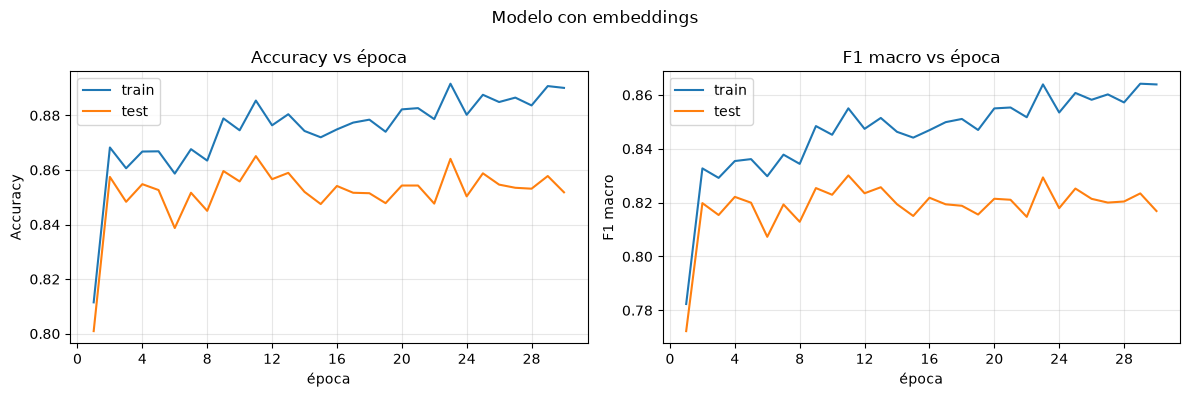

In [27]:
# Arquitectura compartida por los modelos de b) y c): mismas capas, neuronas, activación y épocas
HIDDEN_UNITS = [128, 64, 32]
ACTIVATION = nn.ReLU
EPOCHS = 30

torch.manual_seed(123)

embedding_model = IncomeNet(
    n_input_cols=X_train_processed.shape[1],
    embedding_cardinalities=embedding_cardinalities,
    embedding_dims=embedding_dims,
    hidden_units=HIDDEN_UNITS,
    activation=ACTIVATION,
    dropout_rate=0.25,
)
embedding_model.fit(X_train_processed, y_train_processed, X_test_processed, y_test_processed, criterion, epochs=EPOCHS)

plot_training_curves(embedding_model.history, "Modelo con embeddings")

Modelo con embeddings - classification report sobre validación (adult_val.csv)

              precision    recall  f1-score   support

       <=50K     0.9441    0.8665    0.9037     11360
        >50K     0.6728    0.8424    0.7481      3700

    accuracy                         0.8606     15060
   macro avg     0.8084    0.8545    0.8259     15060
weighted avg     0.8774    0.8606    0.8654     15060



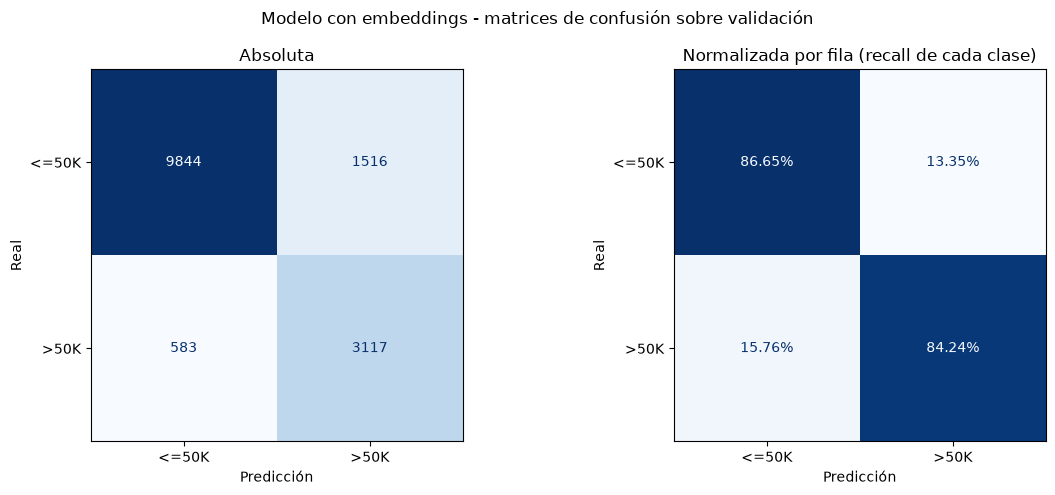

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

def show_validation_results(model, X_val, y_val, title):
    """Classification report y matrices de confusión (absoluta y normalizada por fila) sobre validación."""
    y_val_pred = model.predict(X_val)
    class_names = target_encoder.classes_

    print(f"{title} - classification report sobre validación (adult_val.csv)\n")
    print(classification_report(y_val, y_val_pred, target_names=class_names, digits=4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_val_pred, display_labels=class_names,
        cmap="Blues", values_format="d", colorbar=False, ax=axes[0],
    )
    axes[0].set_title("Absoluta")
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_val_pred, display_labels=class_names, normalize="true",
        cmap="Blues", values_format=".2%", colorbar=False, ax=axes[1],
    )
    axes[1].set_title("Normalizada por fila (recall de cada clase)")
    for ax in axes:
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Real")
    fig.suptitle(f"{title} - matrices de confusión sobre validación")
    plt.tight_layout()
    plt.show()
    return y_val_pred

embedding_val_predictions = show_validation_results(embedding_model, X_val_processed, y_val_processed, "Modelo con embeddings")

## c) Diseño y entrenamiento de un modelo sin embeddings (3 puntos)

- Entrenar un segundo modelo, aplicando one-hot encoding a todas las variables que en el punto b) fueron representadas mediante embeddings.
- Quitar todas las capas de dropout, para este segundo modelo no se usará ninguna capa interna de regularización.
- Con respecto al resto de capas, se debe mantener exactamente la misma arquitectura del modelo anterior: igual número de capas, misma cantidad de neuronas por capa y mismas funciones de activación.
- Presentar las mismas métricas, visualizaciones y reportes que en el modelo con embeddings.

### Preprocesamiento y modelo sin embeddings

Se genera un segundo pipeline con la misma función `build_preprocessor`, idéntico al anterior salvo que `occupation`, `native-country` y `skill-profile` pasan del grupo de embedding al de one-hot. Se ajusta con el mismo set de entrenamiento y se guarda en `preproc_onehot.joblib`.

El modelo mantiene exactamente la misma arquitectura que el del punto b): las mismas capas ocultas, neuronas y función de activación (`HIDDEN_UNITS`, `ACTIVATION`), la misma pérdida (`criterion`), la misma cantidad de épocas y la misma semilla. Las únicas diferencias son las pedidas por la consigna: no tiene capas de embedding (`embedding_cardinalities=[]`) y no tiene dropout (`dropout_rate=0`).

In [29]:
PREPROCESSING_ONEHOT_PATH = "preproc_onehot.joblib"

FEATURE_GROUPS_ONEHOT = {
    **FEATURE_GROUPS_WITH_EMBEDDINGS,
    "onehot": FEATURE_GROUPS_WITH_EMBEDDINGS["onehot"] + FEATURE_GROUPS_WITH_EMBEDDINGS["embedding"],
    "embedding": [],
}

# --- fit solo con train y guardar ---
onehot_preprocessor = build_preprocessor(FEATURE_GROUPS_ONEHOT).fit(X_train)
joblib.dump({"preprocessor": onehot_preprocessor, "target_encoder": target_encoder}, PREPROCESSING_ONEHOT_PATH)

# --- cargar y aplicar a cada set ---
X_train_onehot, y_train_onehot = transform_features_target(X_train, y_train, path=PREPROCESSING_ONEHOT_PATH)
X_test_onehot, y_test_onehot = transform_features_target(X_test, y_test, path=PREPROCESSING_ONEHOT_PATH)
X_val_onehot, y_val_onehot = transform_set(data_test, path=PREPROCESSING_ONEHOT_PATH)

print(f"train: {X_train_onehot.shape}  test: {X_test_onehot.shape}  validación: {X_val_onehot.shape}")

train: (24129, 160)  test: (6033, 160)  validación: (15060, 160)


Época   1/30  (train / test)  loss 0.4940 / 0.5170  acc 0.8488 / 0.8424  F1 macro 0.8176 / 0.8102
Época   2/30  (train / test)  loss 0.4702 / 0.5011  acc 0.8443 / 0.8367  F1 macro 0.8157 / 0.8072
Época   3/30  (train / test)  loss 0.4527 / 0.4930  acc 0.8661 / 0.8553  F1 macro 0.8360 / 0.8233
Época   4/30  (train / test)  loss 0.4624 / 0.5167  acc 0.8886 / 0.8735  F1 macro 0.8556 / 0.8373
Época   5/30  (train / test)  loss 0.4440 / 0.4960  acc 0.8526 / 0.8376  F1 macro 0.8248 / 0.8072
Época   6/30  (train / test)  loss 0.4331 / 0.4988  acc 0.8771 / 0.8599  F1 macro 0.8476 / 0.8272
Época   7/30  (train / test)  loss 0.4245 / 0.4922  acc 0.8697 / 0.8487  F1 macro 0.8416 / 0.8168
Época   8/30  (train / test)  loss 0.4184 / 0.4945  acc 0.8833 / 0.8618  F1 macro 0.8545 / 0.8280
Época   9/30  (train / test)  loss 0.4154 / 0.5009  acc 0.8664 / 0.8435  F1 macro 0.8391 / 0.8122
Época  10/30  (train / test)  loss 0.4056 / 0.5052  acc 0.8842 / 0.8598  F1 macro 0.8561 / 0.8257
Época  11/30  (train

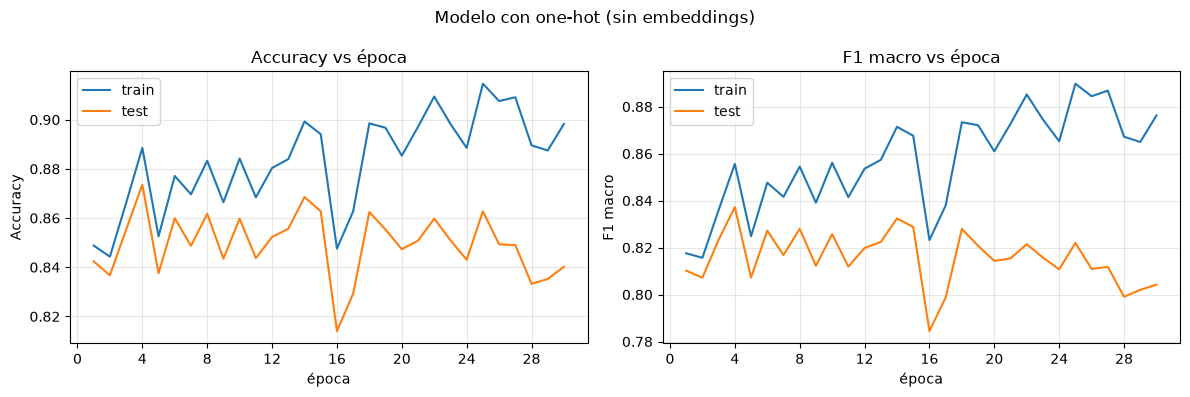

In [30]:
torch.manual_seed(123)

onehot_model = IncomeNet(
    n_input_cols=X_train_onehot.shape[1],
    embedding_cardinalities=[],
    embedding_dims=[],
    hidden_units=HIDDEN_UNITS,
    activation=ACTIVATION,
    dropout_rate=0.0,
)
onehot_model.fit(X_train_onehot, y_train_onehot, X_test_onehot, y_test_onehot, criterion, epochs=EPOCHS)

plot_training_curves(onehot_model.history, "Modelo con one-hot (sin embeddings)")

Modelo con one-hot - classification report sobre validación (adult_val.csv)

              precision    recall  f1-score   support

       <=50K     0.9406    0.8442    0.8898     11360
        >50K     0.6361    0.8362    0.7226      3700

    accuracy                         0.8422     15060
   macro avg     0.7883    0.8402    0.8062     15060
weighted avg     0.8658    0.8422    0.8487     15060



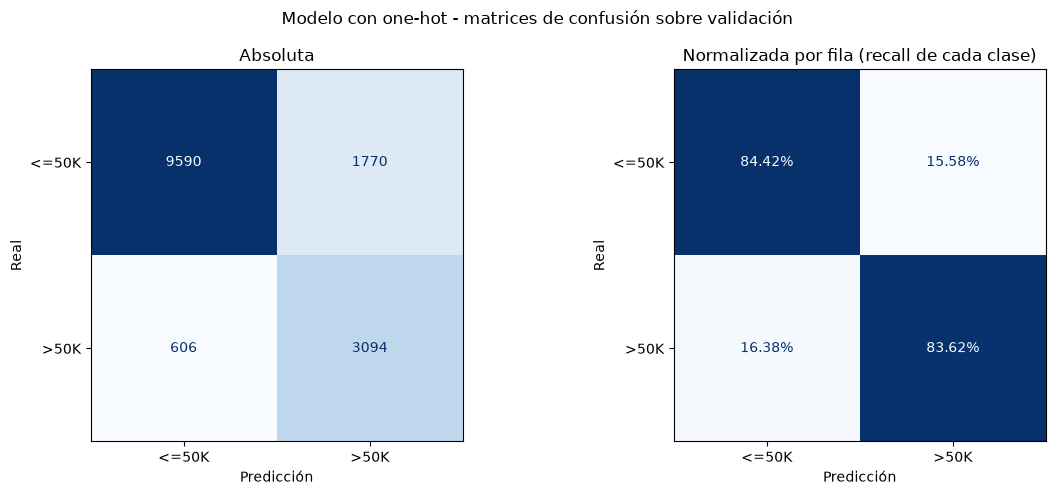

In [31]:
onehot_val_predictions = show_validation_results(onehot_model, X_val_onehot, y_val_onehot, "Modelo con one-hot")


## d) Conclusiones finales (2 puntos)

- Elaborar una tabla comparativa con los resultados obtenidos por ambos modelos. No solo comparar métricas de precisión, sino también la cantidad final de parámetros y entradas.
- Redactar detalladamente sus observaciones y apreciaciones derivadas de la comparación y plantear conclusiones fundamentadas respecto al desempeño de cada enfoque, justificando por qué uno funciona mejor o peor según las características del problema.